In [1]:
"""
Why WebSockets:
- low latency (ideal for image capture and task processing)
- can handle multiple clients by keeping open communication channel (simultaneously)
- more efficient than HTTP (single open connection instead of creating new connections for 
    each request/response

Considerations for using Flask over WebSockets:
- simpler to implement, highly compatible with Jupyter
- good choice if image capture requests are infrequent
- each request is treated independently

hostname -I
--> 172.28.236.86
"""

'\nWhy WebSockets:\n- low latency (ideal for image capture and task processing)\n- can handle multiple clients by keeping open communication channel (simultaneously)\n- more efficient than HTTP (single open connection instead of creating new connections for \n    each request/response\n\nConsiderations for using Flask over WebSockets:\n- simpler to implement, highly compatible with Jupyter\n- good choice if image capture requests are infrequent\n- each request is treated independently\n\nhostname -I\n--> 172.28.236.86\n'

In [2]:
# !pip install websockets

### Connect Jupyter Notebook to WebSocket server

In [3]:
# import asyncio
# import websockets
# import matplotlib.pyplot as plt
# from PIL import Image
# import io
# import json

# async def request_image():
#     """
#     Connects to the WebSocket server, sends a capture command, and processes the response.
#     """
#     uri = "ws://172.28.236.137>:8765"  # Replace <raspberry_pi_ip> with your Raspberry Pi's IP address
#     async with websockets.connect(uri) as websocket:
#         # Send the "capture" command to the server
#         await websocket.send(json.dumps({"action": "capture"}))
#         print("Capture request sent to server.")

#         # Receive the image data or an error message
#         response = await websocket.recv()
#         try:
#             img_data = response
#             image = Image.open(io.BytesIO(img_data))
#             plt.imshow(image)
#             plt.axis("off")
#             plt.show()
#         except Exception as e:
#             print(f"Error: {response}")

# # Run the client
# await request_image()


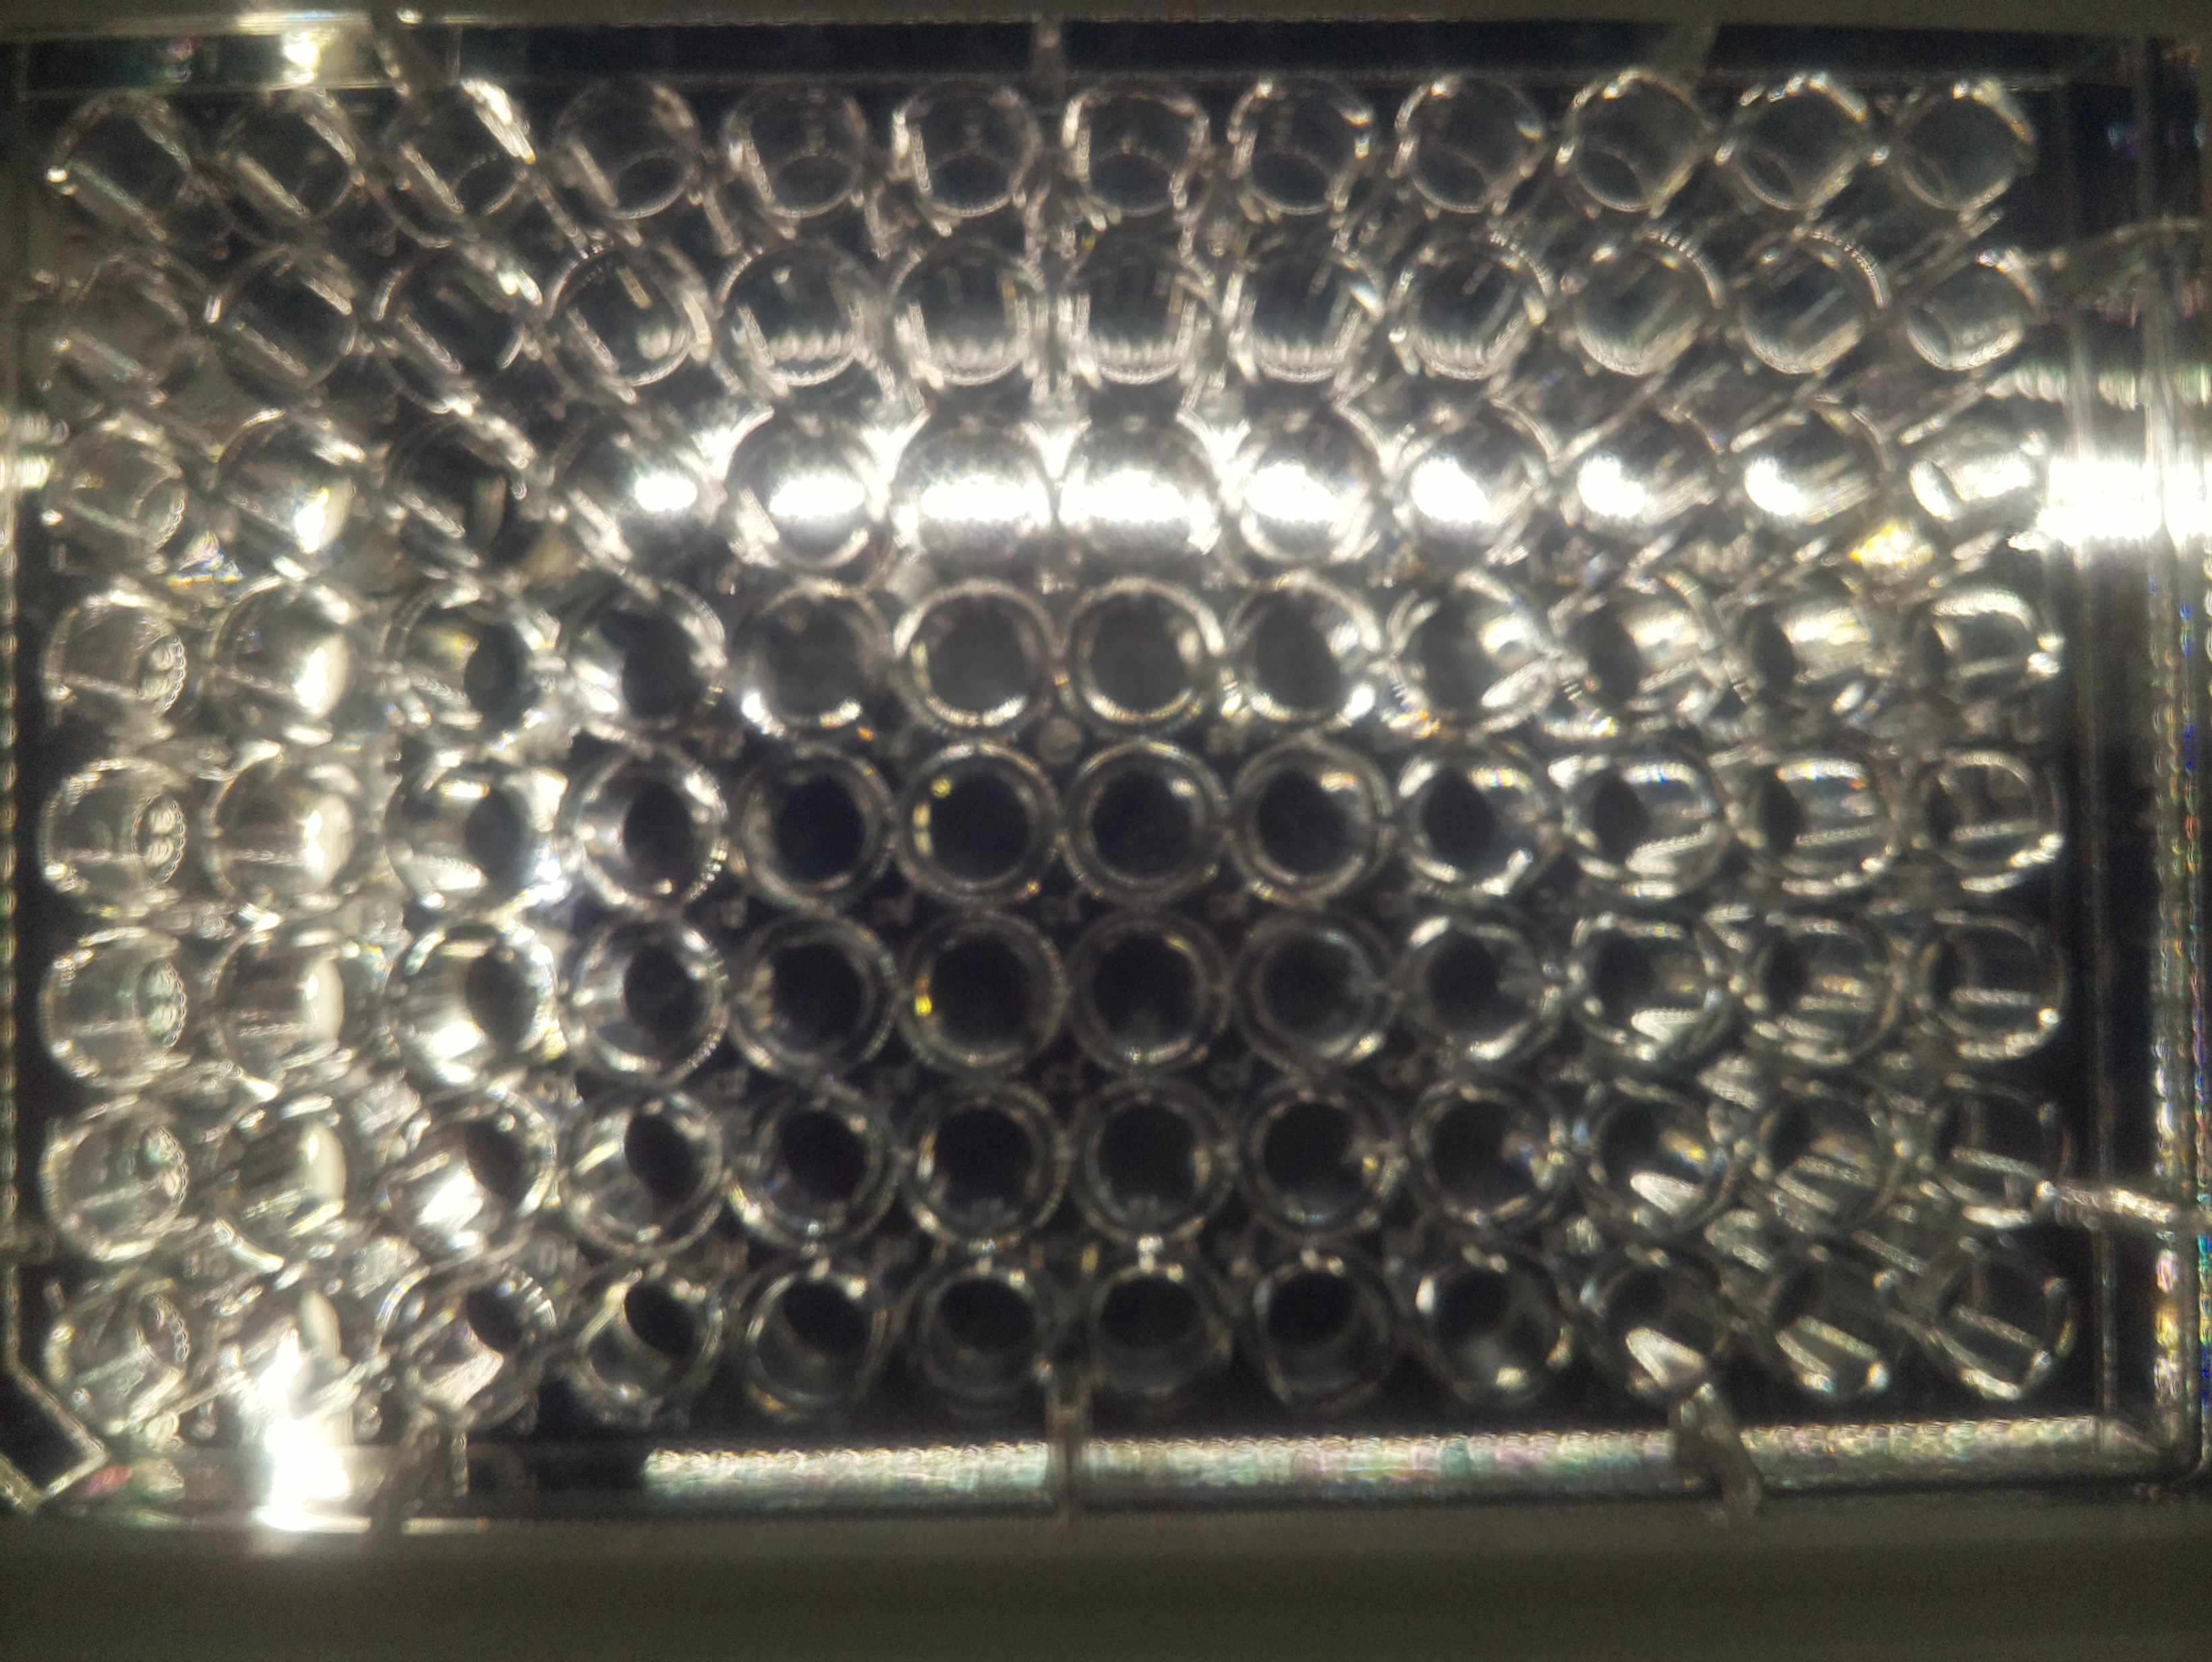

Image captured
Image saved as captured_image.png
None


In [4]:
import asyncio
import websockets
import base64
from IPython.display import display, Image

async def capture_photo():
    uri = "ws://172.28.236.86:8765"
    
    async with websockets.connect(uri, max_size=5_000_000) as websocket:
        # send command to capture
        await websocket.send("capture")
        
        # wait for response
        response = await websocket.recv()
        
        try:
            # decode from Base64
            img_data = base64.b64decode(response)
            
            display(Image(data=img_data, format='jpg'))
            print("Image captured")

            with open("captured_image.png", "wb") as f:
                f.write(img_data)
            print("Image saved as captured_image.png")

        except Exception as e:
            print("Response:", response)
            print("Exception:", e)

result = await capture_photo()
print(result)